# ML training: from baselines to the frozen models

This notebook retraces how Models 1–3 were trained and chosen, using the saved run outputs in `ml/eda/stage*`,
`ml/final/` and `ml/final23/`.

**The rules it follows:**
- **It never re-scores the test sets.** Each test set was scored **once**: Model 1 on 2026-10-25 08:15 UTC, and
  Models 2 and 3 on 2026-10-25 16:08 UTC. The test results shown here are *read* from the saved files.
- **It retrains nothing.** The frozen models are loaded only after their SHA-256 hashes match `FROZEN.json`.
- **Models 2 and 3 are trained on synthetic outcomes.** They demonstrate the method; they are not validated World
  Bank risk models.

**Where the full reports are:** `ml/reports/` (`STAGE_2A…`, `STAGE_2B…`, `STAGE_2C…`, the `MODEL_*_FINAL_*`
reports and the model cards).

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})


def find_ml_dir(start: Path) -> Path:
    """The ml/ folder, whether the notebook runs from ml/notebooks/, ml/ or the project root."""
    for folder in [start, *start.parents]:
        for candidate in (folder, folder / "ml"):
            if (candidate / "eda" / "eda_20261025T070501Z").is_dir():
                return candidate
    raise FileNotFoundError("Run this notebook inside the procurement-intelligence project")


def heatmap(frame: pd.DataFrame, title: str, fmt: str = "{:.0f}", cmap: str = "Blues", counts: pd.DataFrame | None = None,
            center: float | None = None, ax=None, colorbar_label: str = ""):
    """An annotated heatmap of a small table; empty rows are dropped and empty cells stay blank. counts (same shape)
    adds 'n=' under each value."""
    frame = frame.astype(float).dropna(how="all")
    counts = counts.loc[frame.index] if counts is not None else None
    ax = ax or plt.subplots(figsize=(max(6.5, 1.1 * frame.shape[1] + 3), 0.45 * frame.shape[0] + 1.6))[1]
    values = frame.values
    finite = values[np.isfinite(values)]
    if center is None:
        vmin, vmax = finite.min(), finite.max()
    else:
        spread = np.abs(finite - center).max()
        vmin, vmax = center - spread, center + spread
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(frame.shape[1]), [str(c)[:30] for c in frame.columns], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(frame.shape[0]), [str(i)[:38] for i in frame.index], fontsize=8)
    ax.grid(False)
    for (row, col), value in np.ndenumerate(values):
        if np.isnan(value):
            continue
        red, green, blue, _ = image.cmap(image.norm(value))
        dark = 0.299 * red + 0.587 * green + 0.114 * blue < 0.5
        label = fmt.format(value) + (f"\nn={int(counts.iat[row, col])}" if counts is not None else "")
        ax.text(col, row, label, ha="center", va="center", fontsize=7.5, color="white" if dark else "black")
    plt.colorbar(image, ax=ax, fraction=0.04, pad=0.02, label=colorbar_label)
    ax.set_title(title)
    return ax


ML = find_ml_dir(Path.cwd())
print("ML folder:", ML)
import hashlib

import joblib

STAGE = ML / "eda"
M1 = ML / "final" / "frozen"
M23 = ML / "final23" / "frozen"
SPLIT_RUN = STAGE / "stage2a_split_audit_20261025T072430Z"
BASELINE_RUN = STAGE / "stage2a_baselines_20261025T072603Z"
LINEAR_RUN = STAGE / "stage2b_summary_20261025T073816Z"
ADVANCED_RUN = STAGE / "stage2c_comparison_20261025T080300Z"


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_json(path: Path) -> dict:
    return json.loads(path.read_text())

ML folder: /Users/lalith/Documents/my_projects/Procurement AI Assitant Platform/procurement-intelligence/ml


## 1. Integrity: are these the frozen artefacts?

Before anything is loaded, every model file is hashed and compared with the hash recorded when it was frozen.

In [2]:
frozen_m1, frozen_m23 = read_json(M1 / "FROZEN.json"), read_json(M23 / "FROZEN.json")
expected = {f"final/models/{name}": (M1 / "models" / name, digest) for name, digest in frozen_m1["models_sha256"].items()}
expected |= {f"final23/{name}": (M23 / name, digest) for name, digest in frozen_m23["artefacts_sha256"].items()
             if name.endswith(".joblib")}
integrity = pd.DataFrame([{"artefact": key, "matches_frozen_hash": sha256(path) == digest}
                          for key, (path, digest) in expected.items()])
display(integrity)
assert integrity["matches_frozen_hash"].all(), "A frozen artefact has changed: stop here"
print("Test scored once:", read_json(M1 / "TEST_SCORED.json")["note"])

,artefact,matches_frozen_hash
0,final/models/b1_final.joblib,True
1,final/models/rf_final.joblib,True
2,final/models/ridge_final.joblib,True
3,final23/models/m2_S0_l2_final.joblib,True
4,final23/models/m2_S2_l2_final.joblib,True
5,final23/models/m3_S0_l2_final.joblib,True
6,final23/models/m3_S2_l2_final.joblib,True


Test scored once: Test set scored once; do not re-score.


## 2. Model 1: the split

The data is split **by date, not at random**. The model is used on future tenders, so it's evaluated on future
tenders too.
- **Lots stay together:** contracts of one package never sit in two splits.
- **Full follow-up:** only tenders that had time to finish are used, because of the truncation found in the EDA.

In [3]:
audit = read_json(SPLIT_RUN / "split_audit.json")
bounds = audit["checks"]["1_boundaries"]["splits"]
display(pd.DataFrame({split: {"from": b["rule"][0], "to": b["rule"][1], "rows": audit["checks"]["2_totals"]["counts"][split]}
                      for split, b in bounds.items()}).T)
print("Audit checks passed:", {name: check.get("pass") for name, check in audit["checks"].items()})

,from,to,rows
train,2019-07-01,2022-06-30,646
validation,2022-07-01,2023-06-30,353
test,2023-07-01,2024-10-20,616


Audit checks passed: {'1_boundaries': True, '2_totals': True, '3_excluded_valid_labels': True, '4_duplicate_contract_ids': True, '5_package_overlap': True, '6_project_overlap': True, '7_counts': True, '8_feature_availability': True, '9_prediction_date_and_cutoff': True, '10_lots': True}


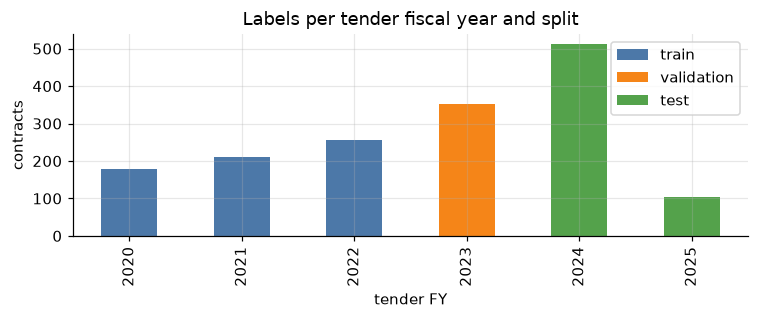

In [4]:
by_year = pd.read_csv(SPLIT_RUN / "counts_by_fiscal_year.csv").set_index("tender_fiscal_year").sort_index()
ax = by_year[["train", "validation", "test"]].plot.bar(stacked=True, figsize=(7, 3),
                                                       color=["#4C78A8", "#F58518", "#54A24B"])
ax.set(title="Labels per tender fiscal year and split", xlabel="tender FY", ylabel="contracts")
plt.tight_layout()

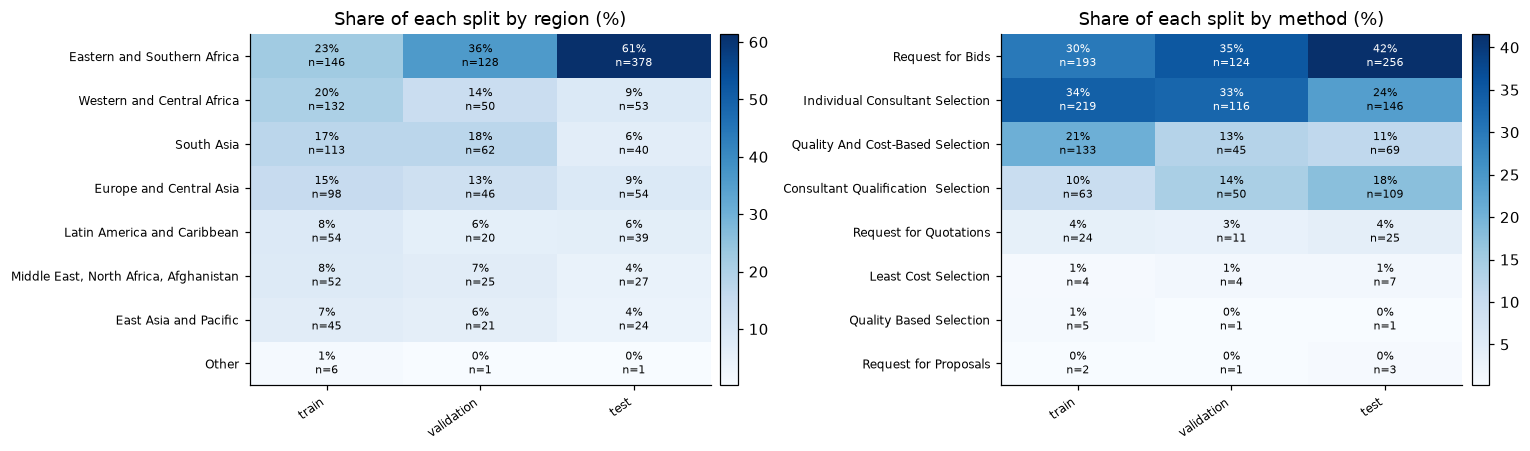

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (name, column) in zip(axes, (("region", "region_name"), ("method", "procurement_method"))):
    counts = pd.read_csv(SPLIT_RUN / f"counts_by_{name}.csv").set_index(column)
    shares = counts[["train", "validation", "test"]].div(counts[["train", "validation", "test"]].sum()) * 100
    shares = shares.loc[counts.sort_values("total", ascending=False).index[:8]]
    heatmap(shares, f"Share of each split by {name} (%)", fmt="{:.0f}%", cmap="Blues",
            counts=counts.loc[shares.index, ["train", "validation", "test"]], ax=ax)
plt.tight_layout()

**The mix shifts between splits.** Eastern and Southern Africa makes up a much larger share of the test set than of
the training set. Results on the test set therefore lean on that region, which is one reason metrics are reported by
segment.

## 3. Baselines first

The baselines are scored on the validation year (FY2023, 353 contracts):
- **B0:** one global median for every tender;
- **B1:** the median for the tender's **method × category**, falling back to a coarser group when a group is small;
- **B1m:** a variant of B1.

Any model has to beat **B1**, which already captures the EDA's main finding.

In [6]:
baselines = read_json(BASELINE_RUN / "baseline_metrics.json")
pd.DataFrame(baselines["validation_metrics"]).T[["n", "MAE", "MedAE", "RMSE", "share_within_30d", "share_within_50pct"]]

,n,MAE,MedAE,RMSE,share_within_30d,share_within_50pct
B0,353.0,104.586,79.0,143.040,0.125,0.431
B1,353.0,82.173,66.5,113.868,0.314,0.586
B1m,353.0,80.901,61.0,113.153,0.306,0.615
B1_package_dedup,353.0,80.908,58.5,113.277,0.295,0.609
B0_asof,353.0,97.785,65.0,146.649,0.221,0.538
B1_asof,353.0,77.479,47.0,116.148,0.346,0.637


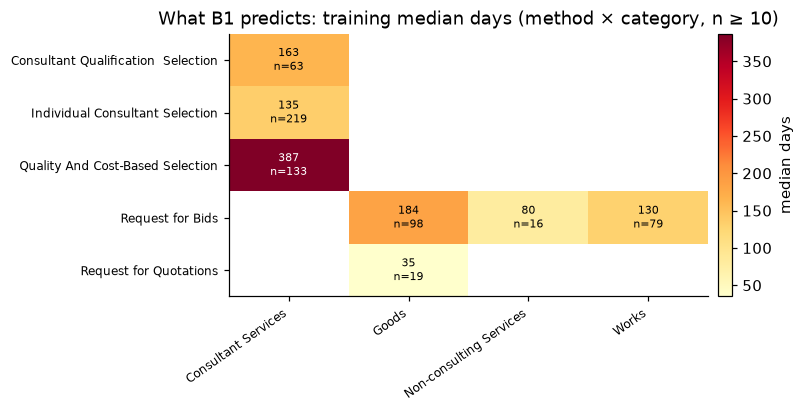

In [7]:
groups = baselines["fitted"]["B1_groups_used"]["procurement_methodxprocurement_category"]
b1 = pd.DataFrame([{"method": key.split("|")[0], "category": key.split("|")[1], **value} for key, value in groups.items()])
b1 = b1[b1["n"] >= 10]
heatmap(b1.pivot(index="method", columns="category", values="median"),
        "What B1 predicts: training median days (method × category, n ≥ 10)",
        counts=b1.pivot(index="method", columns="category", values="n"), cmap="YlOrRd", colorbar_label="median days")
plt.tight_layout()

B1 is literally this lookup table: a new tender gets the training median of its method × category cell. The models
have to add something beyond it.

## 4. Linear models (Stage 2B)

OLS, Ridge, Lasso and ElasticNet on ln(days), with the as-of features. The 95% confidence intervals come from a
**project-cluster bootstrap**: projects are resampled, because labels within a project are correlated.

In [8]:
linear = pd.read_csv(LINEAR_RUN / "comparison.csv")
linear.query("protocol == 'asof'")[["model", "MAE", "MAE_ci_project", "reduction_vs_B1_ci_project",
                                     "P10_P90_coverage", "nonzero_coef", "params"]]

,model,MAE,MAE_ci_project,reduction_vs_B1_ci_project,P10_P90_coverage,nonzero_coef,params
0,B0,97.785,"[78.5, 119.1]","[-31.4, -8.4]",NaN,NaN,NaN
1,B1,77.479,"[61.8, 95.5]",NaN,NaN,NaN,NaN
2,B1m,77.475,"[62.5, 95.2]","[-2.1, 1.6]",NaN,NaN,NaN
3,ols,80.262,"[63.4, 98.7]","[-12.7, 6.4]",0.807,39.0,{}
4,ridge,75.835,"[61.2, 91.0]","[-5.6, 9.0]",0.844,45.0,{'alpha': 10.0}
5,lasso,76.319,"[60.7, 92.3]","[-7.3, 9.0]",0.847,33.0,{'alpha': 0.0031622776601683794}
6,enet,76.646,"[61.3, 92.5]","[-6.8, 8.3]",0.830,42.0,"{'alpha': 0.01, 'l1_ratio': 0.1}"


Ridge has the lowest MAE among the linear models, but its gain over B1 is **not significant**: the confidence
interval of the reduction includes 0.

## 5. Non-linear models (Stage 2C) and long-tender detection

Random forest and XGBoost were compared with Ridge and B1 under a **pre-registered** selection rule. The rule is in
`ml/stage2c/PREREGISTRATION.json`, whose hash was recorded before any result was seen.

Two jobs are measured:
- **MAE:** how many days off the estimate is;
- **long-tender detection:** whether tenders that will take more than 365 days are flagged.

In [9]:
advanced = pd.read_csv(ADVANCED_RUN / "regression_metrics.csv").query("protocol == 'asof'")
display(advanced[["model", "train_MAE", "cv_MAE", "val_MAE", "val_MAE_ci_project", "bias_long_gt365", "P10_P90_coverage"]])

long = pd.read_csv(ADVANCED_RUN / "long_detection.csv")
long.query("protocol == 'asof' and rule.str.startswith('primary')", engine="python")[
    ["model", "PR_AUC", "ROC_AUC", "recall", "precision", "F1", "alert_rate"]]

,model,train_MAE,cv_MAE,val_MAE,val_MAE_ci_project,bias_long_gt365,P10_P90_coverage
0,B1,81.11,91.27,77.479,"[61.8, 95.5]",-223.4,NaN
1,Ridge,66.04,75.93,75.835,"[61.2, 91.0]",-245.2,0.844
2,Random Forest,49.65,82.00,70.684,"[57.9, 85.0]",-209.0,0.878
3,XGBoost,59.01,79.14,76.338,"[60.6, 92.5]",-242.2,0.833


,model,PR_AUC,ROC_AUC,recall,precision,F1,alert_rate
0,B1,0.380,0.754,0.533,0.522,0.527,0.130
3,Ridge,0.447,0.854,0.689,0.484,0.569,0.181
6,Random Forest,0.581,0.861,0.600,0.587,0.593,0.130
9,XGBoost,0.502,0.875,0.422,0.559,0.481,0.096


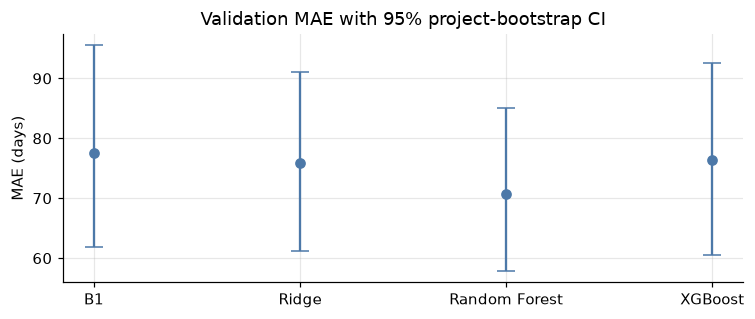

In [10]:
lows, highs = zip(*advanced["val_MAE_ci_project"].map(json.loads))
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(advanced["model"], advanced["val_MAE"],
            yerr=[advanced["val_MAE"] - np.array(lows), np.array(highs) - advanced["val_MAE"]],
            fmt="o", capsize=6, color="#4C78A8")
ax.set(title="Validation MAE with 95% project-bootstrap CI", ylabel="MAE (days)")
plt.tight_layout()

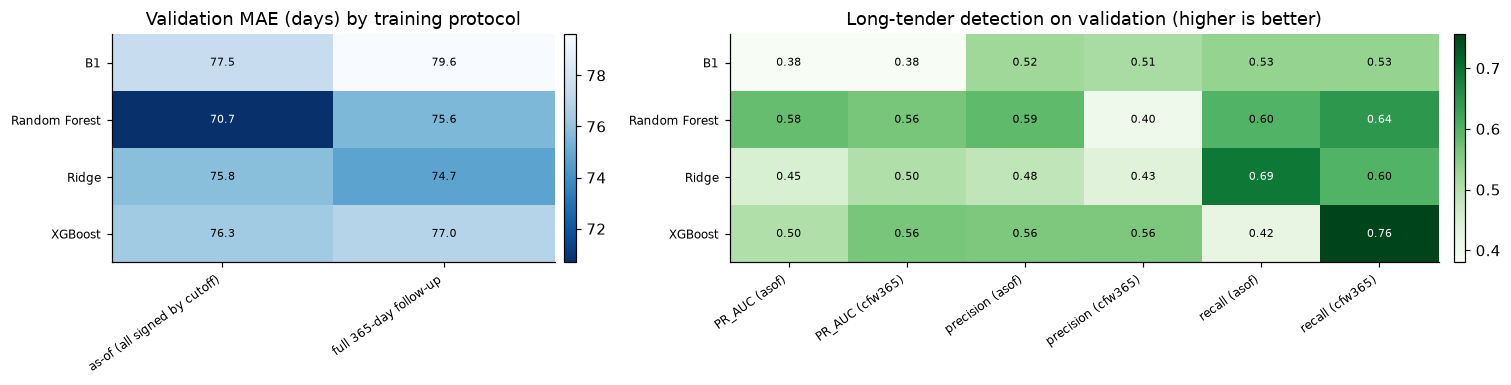

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
protocols = pd.read_csv(ADVANCED_RUN / "protocol_effects.csv").set_index("model")[["asof", "cfw365"]]
protocols.columns = ["as-of (all signed by cutoff)", "full 365-day follow-up"]
heatmap(protocols, "Validation MAE (days) by training protocol", fmt="{:.1f}", cmap="Blues_r", ax=axes[0])

primary = long[long["rule"].str.startswith("primary")]
detection = primary.pivot_table(index="model", columns="protocol", values=["PR_AUC", "recall", "precision"])
detection.columns = [f"{metric} ({protocol})" for metric, protocol in detection.columns]
heatmap(detection, "Long-tender detection on validation (higher is better)", fmt="{:.2f}", cmap="Greens", ax=axes[1])
plt.tight_layout()

- **The confidence intervals overlap almost completely.** On MAE, no model is clearly better than B1.
- **Where the models do add value is long-tender detection:** PR-AUC is about 0.45–0.58, against 0.38 for B1.
- **Every model under-predicts long tenders** (`bias_long_gt365` is about −200 days). That's why the output gives a
  *probability* of exceeding 365 days rather than relying on the point estimate.

## 6. Model 1: the final choice

The pre-registered rule:
- choose the random forest only if it is **convincingly** better than Ridge;
- otherwise choose Ridge, provided it is not significantly worse than B1.

The final models were then refit on train + validation (806 contracts up to 2023-06-30). The alert threshold was set
from out-of-fold training scores, never from the test set.

In [12]:
test_metrics = read_json(M1 / "test_results" / "final_test_metrics.json")
print("Selection rule:", test_metrics["selection_rule_outcome"])

refit = read_json(M1 / "refit_details.json")
print("Refit rows:", refit["refit_audit"]["eligible_rows"], "| projects:", refit["refit_audit"]["projects"])
pd.DataFrame({name: {"params": refit[name].get("best_params"), "cv_MAE_days": refit[name].get("cv_MAE_days"),
                     "alert_threshold": round(refit[name]["alert_threshold"]["t"], 3)}
              for name in ("b1", "ridge", "rf") if name in refit}).T

Selection rule: {'rf_convincing_vs_ridge': False, 'ridge_not_significantly_worse_than_b1': True, 'rule_selects': 'Ridge'}
Refit rows: 806 | projects: 101


,params,cv_MAE_days,alert_threshold
b1,NaN,NaN,0.25
ridge,{'alpha': 31.622776601683793},81.24,0.287
rf,"{'max_depth': None, 'max_features': 0.3, 'min_...",81.87,0.382


## 7. Inside the frozen Ridge model

The model is a scikit-learn pipeline:
- **Categories:** one-hot encoded, with categories under 20 rows treated as "infrequent";
- **Bid window and prior notices:** log1p, then standardised;
- **Other numbers:** standardised;
- **Model:** Ridge on ln(days), with α = 31.6.

On the log scale, a coefficient *b* means "× e<sup>b</sup> days". For numeric features, that's per standard
deviation.

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=20,
                                                                sparse_output=False),
                                                  ['procurement_method',
                                                   'procurement_category',
                                                   'review_type', 'region_name',
                                                   'country_grp', 'sector']),
                                                 ('log',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log1p',
                                                                   FunctionTransformer(feature_...e-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['api_window_days',
                                                   'project_prior_tender_notices']),
                                                 ('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['project_age_days_at_tender',
                                                   'approval_fiscal_year',
                                                   'income_ordinal'])],
                                   verbose_feature_names_out=False)),
                ('model', Ridge(alpha=31.622776601683793))])

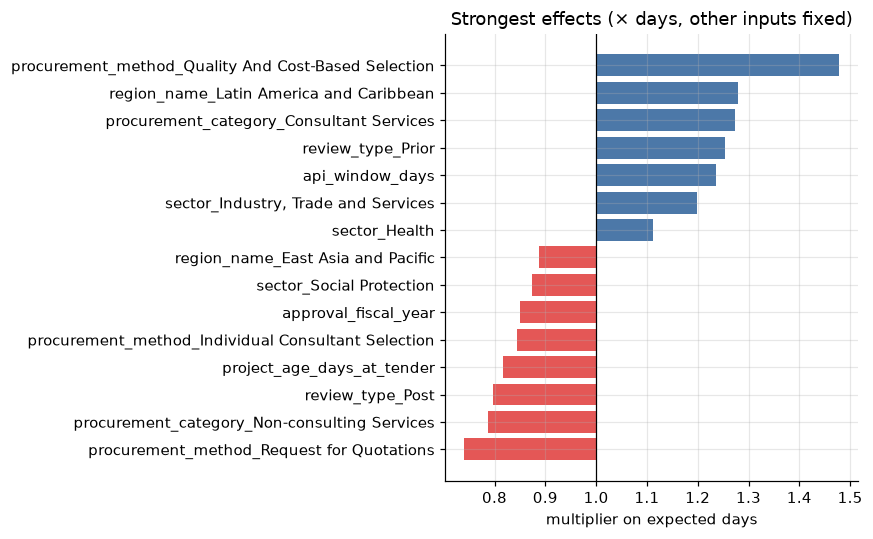

In [13]:
ridge = joblib.load(M1 / "models" / "ridge_final.joblib")     # hash verified in section 1
display(ridge)

names = ridge.named_steps["pre"].get_feature_names_out()
effects = (pd.Series(np.exp(ridge.named_steps["model"].coef_), index=names, name="multiplier_on_days")
           .drop([n for n in names if n.startswith("country_grp_")]))   # country effects are not shown as drivers
top = effects.loc[(effects - 1).abs().sort_values(ascending=False).index[:15]].sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values - 1, left=1, color=["#E45756" if v < 1 else "#4C78A8" for v in top.values])
ax.axvline(1, color="black", lw=0.8)
ax.set(title="Strongest effects (× days, other inputs fixed)", xlabel="multiplier on expected days")
plt.tight_layout()

These match the EDA:
- **Longer:** QCBS, prior review, consultant services, a longer bid window.
- **Shorter:** RFQ, post review, older projects.

These are associations the model learned, not causal effects. Country effects are hidden, so no country is presented
as "slow".

### What the model expects for each method × review type

To see the model as a lookup, take one typical tender and vary only its **method** and **review type**:
- the typical tender is in Eastern and Southern Africa, with median numeric inputs;
- its category follows the method: consultant services for the consulting methods, goods for RFB and RFQ;
- each cell is the frozen Ridge model's expected number of days.

This is a what-if on made-up inputs. It doesn't use test data.

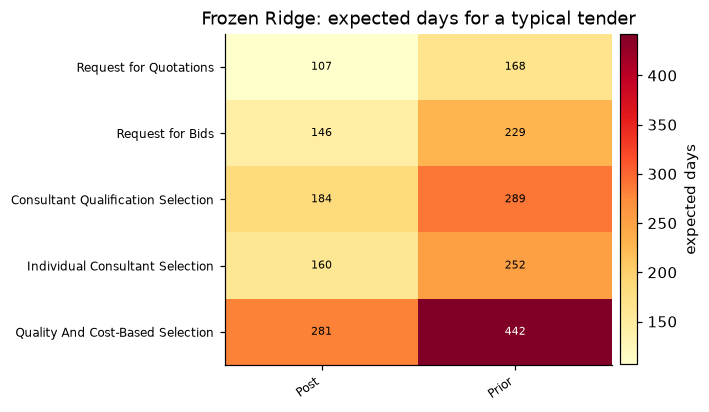

In [14]:
typical = {"region_name": "Eastern and Southern Africa", "country_grp": "ET", "sector": "Transportation",
           "api_window_days": 19, "project_prior_tender_notices": 19, "project_age_days_at_tender": 906,
           "approval_fiscal_year": 2018, "income_ordinal": 1}
category_of = {"Request for Quotations": "Goods", "Request for Bids": "Goods",
               "Consultant Qualification Selection": "Consultant Services",
               "Individual Consultant Selection": "Consultant Services",
               "Quality And Cost-Based Selection": "Consultant Services"}
methods = list(category_of)
grid = pd.DataFrame([{**typical, "procurement_method": m, "procurement_category": category_of[m], "review_type": r}
                     for m in methods for r in ("Post", "Prior")])
grid["expected_days"] = np.exp(ridge.predict(grid[list(ridge.named_steps["pre"].feature_names_in_)]))
heatmap(grid.pivot(index="procurement_method", columns="review_type", values="expected_days").loc[methods],
        "Frozen Ridge: expected days for a typical tender", cmap="YlOrRd", colorbar_label="expected days")
plt.tight_layout()

## 8. One prediction, through the app's own serving code

This uses the same code path as the assistant (`ml.serving.models.FrozenModels`), which re-checks the hashes. The
tender below is **made up** for illustration; it isn't from the test set.

In [15]:
import sys

PROJECT_ROOT = ML.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from ml.serving.models import FrozenModels

example_tender = {
    "procurement_method": "Quality And Cost-Based Selection", "procurement_category": "Consultant Services",
    "review_type": "Prior", "region_name": "Eastern and Southern Africa", "country_grp": "ET",
    "sector": "Transportation", "api_window_days": 30, "project_prior_tender_notices": 12,
    "project_age_days_at_tender": 400, "approval_fiscal_year": 2019, "income_ordinal": 1,
}
prediction, warnings = FrozenModels().duration(example_tender)
print(f"Expected: {prediction.days} days (P10–P90: {prediction.p10_days}–{prediction.p90_days})")
print(f"P(> 365 days): {prediction.probability_over_365:.0%} | long-tender alert: {prediction.long_tender_alert}")
for driver in prediction.drivers:
    print(f"  - {driver.label}: {driver.effect}")
print("Warnings:", warnings or "none")

Expected: 536 days (P10–P90: 247–1191)
P(> 365 days): 71% | long-tender alert: True
  - Procurement method: +48% longer than average
  - Procurement category: +27% longer than average
  - Review type: +25% longer than average
Warnings: none


## 9. Model 1 test results (read from the single scoring run)

- **Test set:** 616 contracts, tenders published 2023-07 → 2024-10, from 59 projects.
- **Nothing is predicted here.** The predictions and metrics were saved when the test set was scored.

In [16]:
regression = pd.DataFrame(test_metrics["regression"]).T
display(regression[["n", "MAE", "MedAE", "RMSE", "bias_mean_pred_minus_actual", "share_within_50pct"]]
        .join(regression.get("P10_P90_coverage")))

long_test = pd.DataFrame({model: {"PR_AUC": d["PR_AUC"], "ROC_AUC": d["ROC_AUC"],
                                  **{k: d["at_frozen_threshold"][k] for k in ("recall", "precision", "F1", "alert_rate")},
                                  "recall_at_20%_capacity": d["top20pct_capacity"]["recall"]}
                          for model, d in test_metrics["long_detection"].items()}).T
long_test.round(3)

,n,MAE,MedAE,RMSE,bias_mean_pred_minus_actual,share_within_50pct,P10_P90_coverage
b1,616.0,74.338,55.000,108.005,-27.334,0.667,NaN
ridge,616.0,76.666,62.356,106.534,-37.295,0.627,0.838
rf,616.0,73.473,47.577,105.070,-42.991,0.659,0.771


,PR_AUC,ROC_AUC,recall,precision,F1,alert_rate,recall_at_20%_capacity
b1,0.373,0.768,0.594,0.521,0.555,0.119,0.672
ridge,0.537,0.905,0.391,0.556,0.459,0.073,0.828
rf,0.557,0.919,0.297,0.679,0.413,0.045,0.859


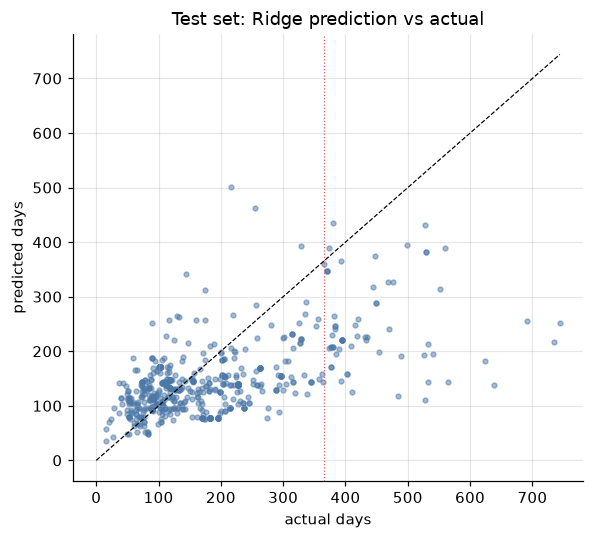

In [17]:
predictions = pd.read_csv(M1 / "test_results" / "test_predictions_with_outcomes.csv")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(predictions["duration_days"], predictions["pred_ridge"], s=10, alpha=0.5, color="#4C78A8")
limit = predictions[["duration_days", "pred_ridge"]].max().max()
ax.plot([0, limit], [0, limit], color="black", lw=0.8, ls="--")
ax.axvline(365, color="#E45756", lw=0.8, ls=":")
ax.set(title="Test set: Ridge prediction vs actual", xlabel="actual days", ylabel="predicted days")
plt.tight_layout()

In [18]:
segments = pd.DataFrame(test_metrics["segments"]["procurement_method"])
display(segments[["segment", "n", "projects", "actual_median", "MAE_b1", "MAE_ridge", "MAE_rf"]])
print("Concentration:", test_metrics["concentration"])

,segment,n,projects,actual_median,MAE_b1,MAE_ridge,MAE_rf
0,Request for Bids,256,39,135.0,73.9,65.3,68.6
1,Individual Consultant Selection,146,31,122.5,66.0,69.8,70.2
2,Consultant Qualification Selection,109,16,104.0,57.1,74.7,58.3
3,Quality And Cost-Based Selection,69,23,371.0,99.8,139.3,120.7
4,Request for Quotations,25,12,77.0,74.1,43.7,45.0
5,Least Cost Selection,7,5,251.0,157.4,164.4,179.2
6,Request for Proposals,3,2,221.0,359.8,83.7,112.6
7,Quality Based Selection,1,1,233.0,89.0,63.6,46.1


Concentration: {'top5_projects_rows': 324, 'top5_share_pct': 52.6, 'MAE_excluding_top5': {'b1': 87.1, 'ridge': 72.4, 'rf': 66.7}, 'long_F1_excluding_top5': {'b1': 0.469, 'ridge': 0.375, 'rf': 0.4}, 'project_MAE_wins': {'b1': 18, 'ridge': 17, 'rf': 25}, 'MAE_top5_only': {'b1': 62.9, 'ridge': 80.5, 'rf': 79.6}}


### Test results as charts

Every chart below is drawn from the saved results of the single scoring run.

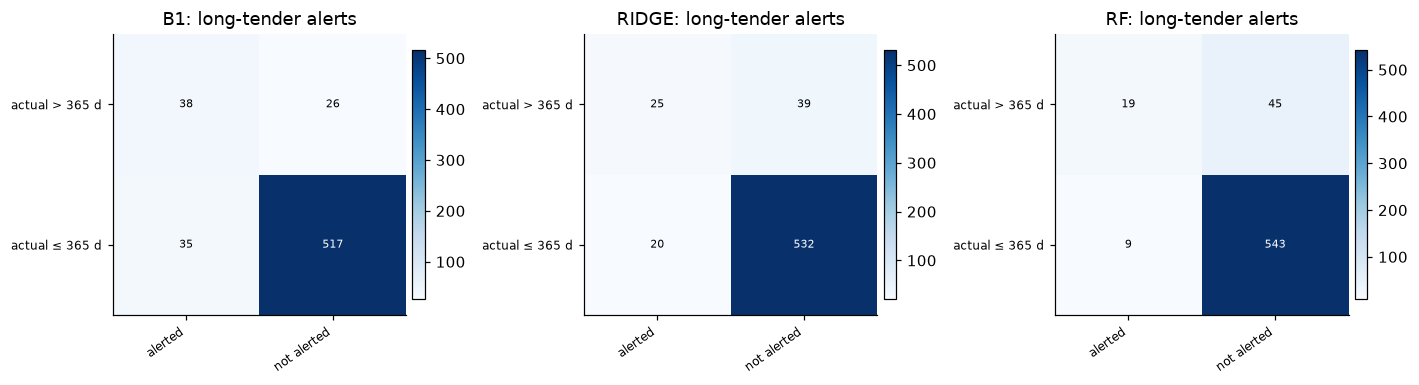

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, model in zip(axes, ("b1", "ridge", "rf")):
    c = test_metrics["long_detection"][model]["at_frozen_threshold"]
    matrix = pd.DataFrame([[c["TP"], c["FN"]], [c["FP"], c["TN"]]],
                          index=["actual > 365 d", "actual ≤ 365 d"], columns=["alerted", "not alerted"])
    heatmap(matrix, f"{model.upper()}: long-tender alerts", fmt="{:.0f}", cmap="Blues", ax=ax)
plt.tight_layout()

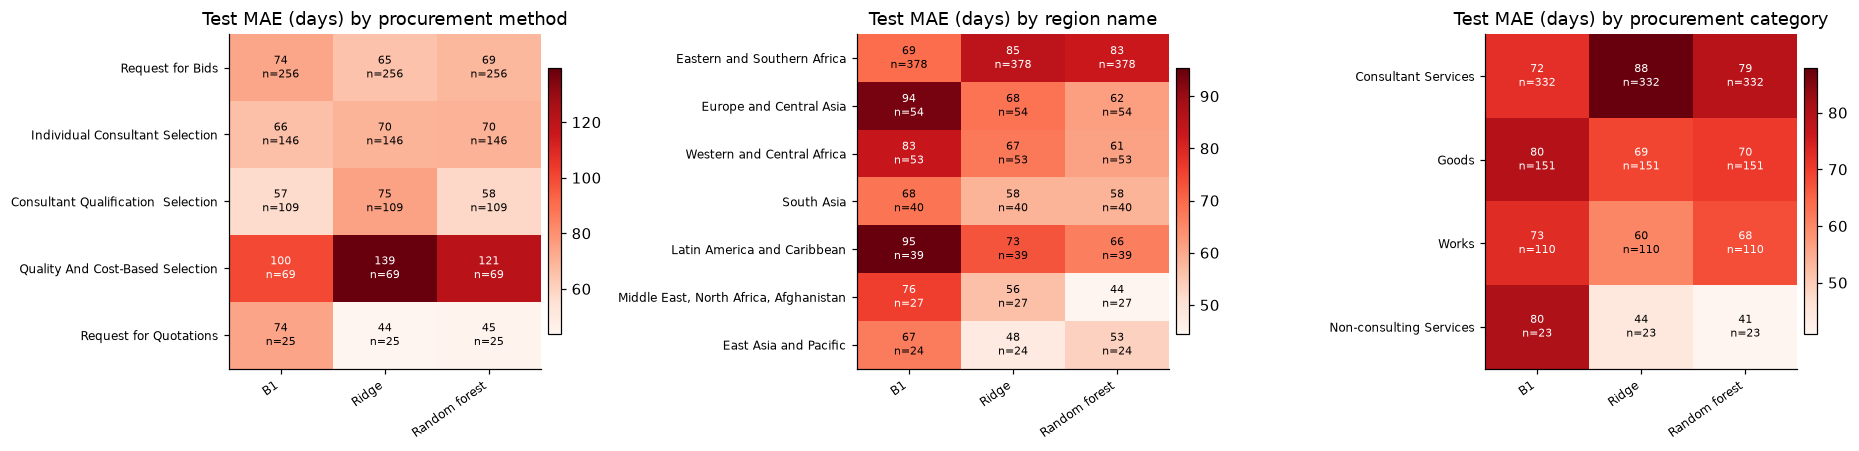

In [20]:
MODELS = {"MAE_b1": "B1", "MAE_ridge": "Ridge", "MAE_rf": "Random forest"}


def segment_mae(dimension: str, top: int = 8) -> tuple[pd.DataFrame, pd.DataFrame]:
    frame = pd.DataFrame(test_metrics["segments"][dimension]).query("not sparse_n_lt_20")
    frame = frame.sort_values("n", ascending=False).head(top).set_index("segment")
    return frame[list(MODELS)].rename(columns=MODELS), pd.DataFrame({m: frame["n"] for m in MODELS.values()})


fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, dimension in zip(axes, ("procurement_method", "region_name", "procurement_category")):
    mae, counts = segment_mae(dimension)
    heatmap(mae, f"Test MAE (days) by {dimension.replace('_', ' ')}", counts=counts, cmap="Reds", ax=ax)
plt.tight_layout()

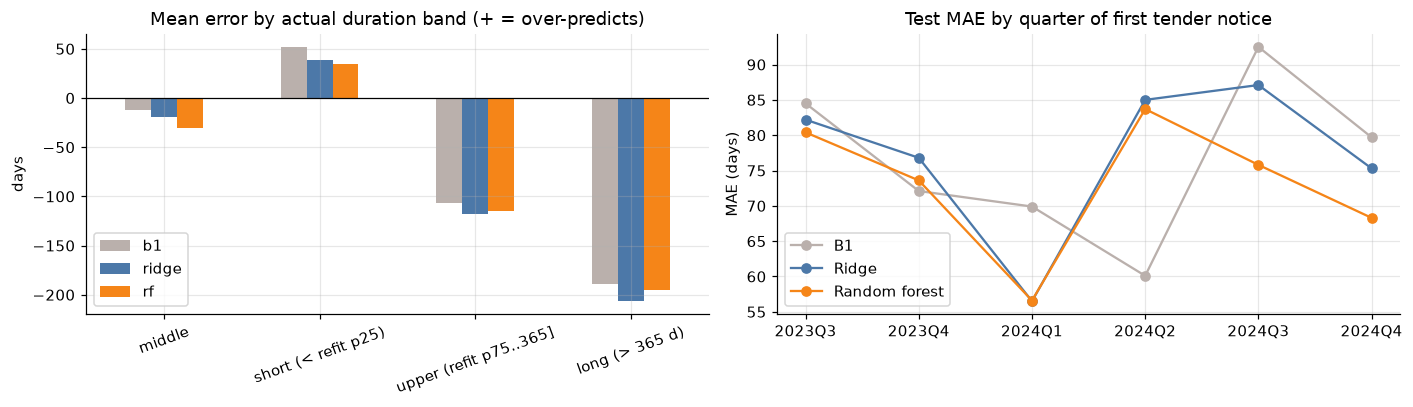

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bands = pd.DataFrame(test_metrics["segments"]["duration_band"]).set_index("segment")
bands[["bias_b1", "bias_ridge", "bias_rf"]].rename(columns=lambda c: c.replace("bias_", "")).plot.bar(
    ax=axes[0], color=["#BAB0AC", "#4C78A8", "#F58518"])
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(title="Mean error by actual duration band (+ = over-predicts)", xlabel="", ylabel="days")
axes[0].tick_params(axis="x", rotation=20)

quarters = pd.DataFrame(test_metrics["segments"]["quarter"]).set_index("segment").sort_index()
for column, color in (("MAE_b1", "#BAB0AC"), ("MAE_ridge", "#4C78A8"), ("MAE_rf", "#F58518")):
    axes[1].plot(quarters.index, quarters[column], marker="o", color=color, label=MODELS[column])
axes[1].set(title="Test MAE by quarter of first tender notice", ylabel="MAE (days)")
axes[1].legend()
plt.tight_layout()

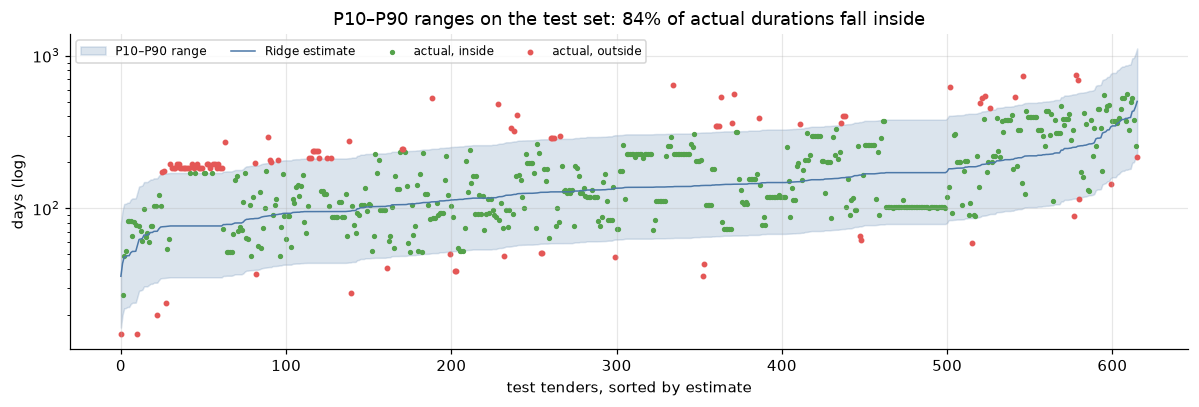

In [22]:
ordered = predictions.sort_values("pred_ridge").reset_index(drop=True)
inside = ordered["duration_days"].between(ordered["lo_ridge"], ordered["hi_ridge"])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ordered.index, ordered["lo_ridge"], ordered["hi_ridge"], color="#4C78A8", alpha=0.2, label="P10–P90 range")
ax.plot(ordered.index, ordered["pred_ridge"], color="#4C78A8", lw=1, label="Ridge estimate")
ax.scatter(ordered.index[inside], ordered.loc[inside, "duration_days"], s=6, color="#54A24B", label="actual, inside")
ax.scatter(ordered.index[~inside], ordered.loc[~inside, "duration_days"], s=8, color="#E45756", label="actual, outside")
ax.set_yscale("log")
ax.set(title=f"P10–P90 ranges on the test set: {inside.mean():.0%} of actual durations fall inside",
       xlabel="test tenders, sorted by estimate", ylabel="days (log)")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()

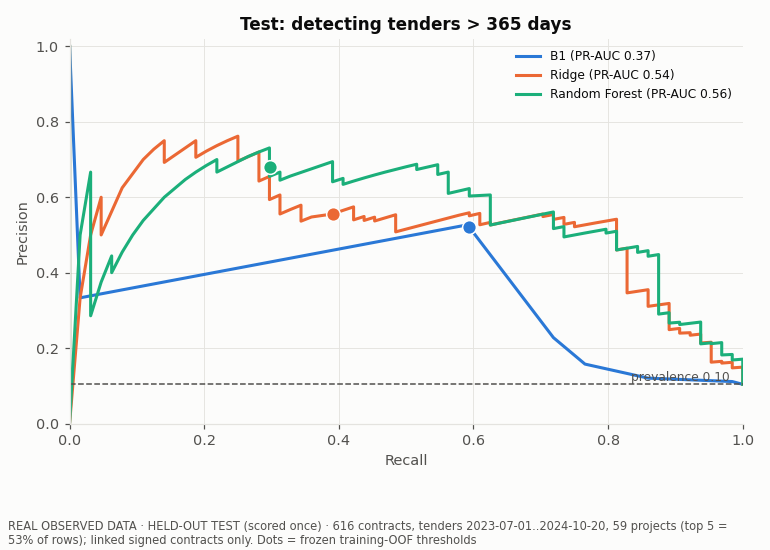

In [23]:
from IPython.display import Image, display

display(Image(filename=str(M1 / "test_results" / "charts" / "02_test_pr_curves.png"), width=700))

**How to read this:**
- **On MAE, Ridge ties with B1** (76.7 vs 74.3 days; the difference is not significant).
- **Ridge is clearly better at ranking long tenders:** PR-AUC 0.54 vs 0.37. At a 20% review capacity it catches 83%
  of them.
- **Weak spots:**
  - long tenders are under-predicted, by about 200 days;
  - QCBS has the largest errors;
  - 5 projects hold 53% of the test rows.

The scatter shows why the app reports a range and a probability, not just the point estimate.

## 10. Models 2 and 3: amendment and re-bid risk (SYNTHETIC outcomes)

> **SYNTHETIC OUTCOMES. NOT VALIDATED WORLD BANK RISK ACCURACY.**

There are no public amendment or re-bid records, so the outcomes were **simulated** from documented assumptions
(`ml/synthetic/configs/sim_v1.json`) on top of **real** contract and tender features.

Each model is checked against a **null twin** (S0), trained on outcomes that ignore every feature. A sound pipeline
must score at chance (ROC-AUC about 0.5) on S0. If it scored higher, it would be finding a signal that isn't there.

In [24]:
m23 = read_json(M23 / "test_results" / "final_test_metrics_m23.json")
print(m23["disclaimer"])
rows = []
for model, label in (("m2", "Model 2: amendment within 24 months"), ("m3", "Model 3: re-bid within 12 months")):
    for scenario in ("S2", "S0"):
        overall = m23["models"][model][scenario]["overall"]
        rows.append({"model": label, "scenario": scenario + (" (null control)" if scenario == "S0" else ""),
                     **{k: overall[k] for k in ("n", "realised_prevalence", "PR_AUC", "ROC_AUC", "Brier", "ECE")}})
pd.DataFrame(rows).set_index(["model", "scenario"]).round(3)

SYNTHETIC OUTCOMES — NOT VALIDATED WORLD BANK RISK ACCURACY


n  realised_prevalence  PR_AUC  ROC_AUC  Brier    ECE
model                               scenario                                                                    
Model 2: amendment within 24 months S2                 28949                0.138   0.232    0.655  0.114  0.014
                                    S0 (null control)  28949                0.152   0.154    0.504  0.129  0.005
Model 3: re-bid within 12 months    S2                 20954                0.082   0.334    0.735  0.065  0.012
                                    S0 (null control)  20954                0.080   0.080    0.500  0.074  0.013

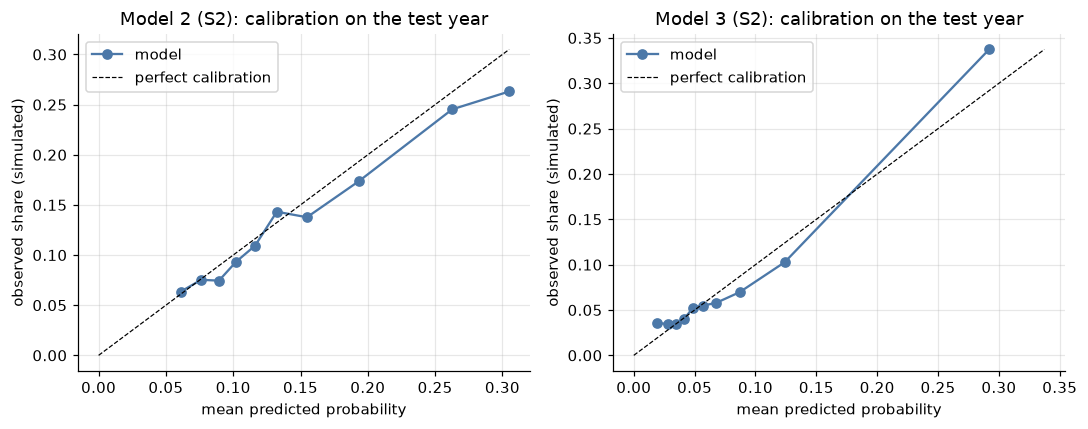

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (model, title) in zip(axes, (("m2", "Model 2 (S2)"), ("m3", "Model 3 (S2)"))):
    bins = m23["models"][model]["S2"]["overall"]["calibration_bins"]
    ax.plot(bins["mean_predicted"], bins["observed"], marker="o", color="#4C78A8", label="model")
    edge = max(max(bins["mean_predicted"]), max(bins["observed"]))
    ax.plot([0, edge], [0, edge], color="black", lw=0.8, ls="--", label="perfect calibration")
    ax.set(title=f"{title}: calibration on the test year", xlabel="mean predicted probability",
           ylabel="observed share (simulated)")
    ax.legend()
plt.tight_layout()

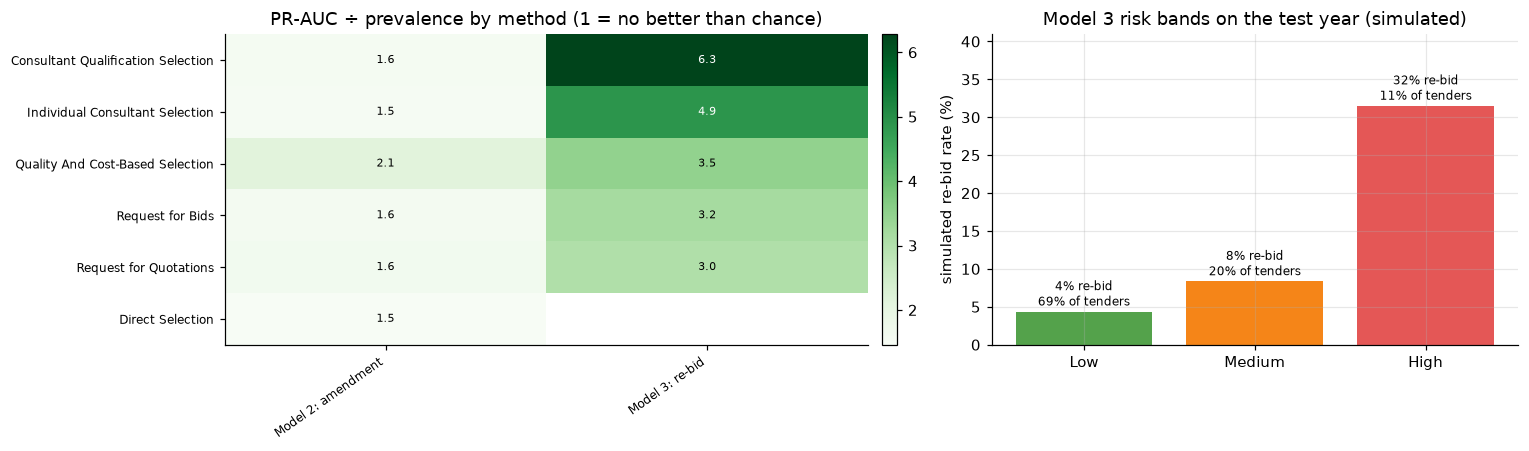

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
by_method = {}
for model, label in (("m2", "Model 2: amendment"), ("m3", "Model 3: re-bid")):
    frame = pd.DataFrame(m23["models"][model]["S2"]["segments"]["procurement_method"]).set_index("segment")
    by_method[label] = frame["PR_AUC"] / (frame["positives"] / frame["n"])
lift = pd.DataFrame(by_method)
lift = lift.loc[lift.notna().sum(axis=1).sort_values(ascending=False).index].head(9)
heatmap(lift, "PR-AUC ÷ prevalence by method (1 = no better than chance)", fmt="{:.1f}", cmap="Greens", ax=axes[0])

bands = pd.DataFrame(m23["models"]["m3"]["S2"]["risk_bands"]).T.loc[["Low", "Medium", "High"]]
axes[1].bar(bands.index, bands["simulated_event_rate"].astype(float) * 100, color=["#54A24B", "#F58518", "#E45756"])
for x, (share, rate) in enumerate(zip(bands["share"].astype(float), bands["simulated_event_rate"].astype(float))):
    axes[1].text(x, rate * 100 + 0.8, f"{rate:.0%} re-bid\n{share:.0%} of tenders", ha="center", fontsize=8)
axes[1].set(title="Model 3 risk bands on the test year (simulated)", ylabel="simulated re-bid rate (%)",
            ylim=(0, bands["simulated_event_rate"].astype(float).max() * 130))
plt.tight_layout()

- **The null twins sit at chance** (ROC-AUC 0.50), so the pipeline doesn't invent a signal.
- **The risk bands separate as designed:** "High" tenders re-bid about 7 times as often as "Low" ones in the
  simulation.
- **Method matters more for Model 3:** it ranks consulting tenders 5–6 times better than chance, and RFB and RFQ
  about 3 times. Model 2's ranking barely varies by method (1.5–2.1 times chance). Both patterns come from the
  effects written into the simulator.
- **The S2 models recover part of the simulated signal and are well calibrated** (ECE about 0.01).
- **But every number here measures agreement with our own assumptions, not real World Bank risk.** A real model needs
  STEP amendment and re-bid records.

## Summary

| Model | Data | Chosen model | Test result | Status |
|---|---|---|---|---|
| 1. Tender duration | Real: 2,114 labels (806 used to refit) | Ridge on ln(days), α 31.6 | MAE 76.7 days (B1 74.3); long-tender PR-AUC 0.54 vs 0.37 | Decision support; frozen |
| 2. Amendment risk | Real features, **synthetic** outcomes | L2 logistic | PR-AUC 0.23 (prevalence 0.14); null control 0.50 ROC-AUC | Demonstration only |
| 3. Re-bid risk | Real features, **synthetic** outcomes | L2 logistic | PR-AUC 0.33 (prevalence 0.08); null control 0.50 ROC-AUC | Demonstration only |

**What would improve Model 1 most:**
1. Notice references for all 2,000 projects. Only 184 are linkable today.
2. Planned dates and estimated amounts from procurement plans. These would allow predictions at the planning stage.
3. Notice-status snapshots, so that cancelled tenders can be studied too.